# Material de aula - FACENS - Aprendizado de Máquina

# <center> RESOLUÇÃO DA ATIVIDADE </center>


## Particle Swarm Optimization - Laboratório 05

In [1]:
#CÉLULA PSO-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
from enum import Enum
from operator import xor
%matplotlib inline

In [2]:
#CÉLULA PSO-LIB-02
def fitness(particle) :  
    '''
    Esta função calcula a aptidão (custo) de uma dada partícula a partir de seus parâmetros.
    
    Parâmetro
    ---------
    particle -> descritor da partícula, no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    O valor de aptidão calculado para a partícula.
    '''
    
    x = particle['X']
    y = particle['Y']
    
    num = (np.sin(np.sqrt(x**2+y**2)))**2 - 0.5
    den = (1 + 0.001*(x**2+y**2)) ** 2
    z = 0.5 - (num / den)

    return z

In [3]:
#CÉLULA PSO-LIB-03
def plot_population(vParticles, generation):
    '''
    Esta função plota o gráfico de um dado bando de partículas, para uma dada geração, em função de suas posições.
    
    Parâmetros
    ----------
     vParticles -> um array de descritores de partículas, cada qual no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    generation  -> indicador da geração da população
    
    Retorno
    -------
    N/A
    '''
    xmin =-100
    xmax = 100
    ymin =-100
    ymax = 100
    
    xAxis = []
    yAxis = []
    for particle in vParticles : #pega as partículas do bando        
        x = particle['X']
        y = particle['Y']
        
        xAxis.append(x)
        yAxis.append(y)
    
    plt.figure()
    plt.plot(xAxis, yAxis, 'bo')
    plt.axis([xmin, xmax, ymin, ymax])
    
    plt.xlabel('x')
    plt.ylabel('y')
    sTitle = ('Populacao na geração {}'.format(generation))
    plt.title(sTitle)
    plt.grid()

In [4]:
#CÉLULA PSO-LIB-04
def calcPBest(particle) :
    '''
    Esta função verifica se a posição atual da partícula é melhor que a sua melhor posição de todos os tempos e atualiza a 
    informação, se necessário.
    
    Parâmetro
    ---------
    particle -> descritor da partícula, no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    Uma tupla (xBest, yBest) com as coordenadas das melhores posições de todos os tempos de uma dada partícula 
    '''
    xBest = particle['XBest']
    yBest = particle['YBest']
    
    particleBest = {'X' : xBest, 'Y' : yBest, 'XBest' : xBest, 'YBest' : yBest, 'VX' : 0, 'VY':0 }
    
    if (fitness(particle) >= fitness(particleBest)) :
        xBest = particle['X']
        yBest = particle['Y']
                
    return (xBest, yBest)

In [5]:
#CÉLULA PSO-LIB-05
def calcAllPBest(vParticles) :
    '''
    Esta função verifica e atualiza o atributo pBest (a melhor posição de uma partícula) para todas as partículas 
    da população a partir de seus respectivos parâmetros.
    
    Parâmetro
    ---------
    vParticles -> um array de descritores de partículas, cada qual no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    Um array de valores de aptidão calculados para todas as partículas, alinhado com o array vParticles.
    '''    
    vParticlesRet = []
    
    for particle in vParticles :
        (x, y) = calcPBest(particle)
        particle['XBest'] = x
        particle['YBest'] = y
                    
        vParticlesRet.append(particle)
    
    return vParticlesRet

In [6]:
#CÉLULA PSO-LIB-06
def calcGBest(vParticles) :
    '''
    Esta função verifica a melhor posição do bando e retorna suas coordenadas.
    
    Parâmetro
    ---------
    vParticles -> array contendo descritores de partícula, no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    Um dicionario no formato {'X' : x, 'Y' : y, 'Fitness' : maxFitness} com as coordenadas da melhor posição de todos
    os tempos do bando bem como o valor de fitness associado a esta posição
    '''
    #Inicializa variavel
    calcAllPBest(vParticles)
    maxFitness = fitness(vParticles[0])

    for particle in vParticles :
        x = particle['XBest']
        y = particle['YBest']
        particleBest = {'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : 0, 'VY':0 }

        currentFitness = fitness(particleBest)
        if ( currentFitness >= maxFitness ) :
            maxFitness = currentFitness
            gBest = {'X' : x, 'Y' : y, 'Fitness' : maxFitness}
    
    return gBest

## PSO - inicio

In [7]:
#CÉLULA PSO-MAIN-01
#Parâmetros
size_pop   = 100
max_generations = 100
stop_condition = 0.95

#Limites do dominio de definição
x_min = -100
x_max =  100

y_min = -100
y_max =  100


# Cada particula tem dados (X,Y, XBest, YBest)
gBest = {'X' : 0, 'Y' : 0, 'Fitness' : 0}
vParticles = []

deltaT = 1
c1 = 0.2
c2 = 0.3
w  = 0.2

vMax = 500 #limitação de velocidade

#r1 e r2 deverão ser extraídas de uma distribuição uniforme e são atualizadas a cada cálculo de velocidade da população
#as melhores posições, individual e global, são obtidas através da função de fitness

In [8]:
#CÉLULA PSO-MAIN-02
#Inicializando população
vParticles=[]

for _ in range(0, size_pop):
    x   =  x_min + np.random.random() * (x_max - x_min)
    y   =  y_min + np.random.random() * (y_max - y_min)
    vx  = (x_min + np.random.random() * (x_max - x_min)) / deltaT
    vy  = (y_min + np.random.random() * (y_max - y_min)) / deltaT
    vParticles.append({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })

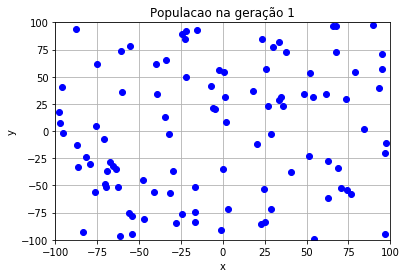

In [9]:
plot_population(vParticles, 1)

In [10]:
#CÉLULA PSO-MAIN-03
def runEpoch(vParticles) :
        #Atualizando vetor de velocidades
    r1 = np.random.random()
    r2 = np.random.random()

    #Calcula gbest
    gBest = calcGBest(vParticles)    
    
    for particle in vParticles :
        
        #Atualiza pbest
        (xBest, yBest) = calcPBest(particle)
        particle['XBest'] = xBest
        particle['YBest'] = yBest        
        
        #Atualiza gbest
        currentGBest = calcGBest(vParticles)
        particleTemp = {'X' : currentGBest['X'], 'Y' : currentGBest['Y'], 'XBest' : 0, 'YBest' : 0, 'VX' : 0, 'VY':0 }        
        particleGBest = {'X' : gBest['X'], 'Y' : gBest['Y'], 'XBest' : 0, 'YBest' : 0, 'VX' : 0, 'VY':0 }
        
        if(fitness(particleTemp) > fitness(particleGBest)) :
            gBest = currentGBest
        
        #Atualiza velocidade de uma particula
        newVX = w*particle['VX'] + c1*r1*(particle['XBest'] - particle['X']) + c2*r2*(gBest['X'] - particle['X'])
        newVY = w*particle['VY'] + c1*r1*(particle['YBest'] - particle['Y']) + c2*r2*(gBest['Y'] - particle['Y'])
                
        #Verifica limite de velocidade
        if (newVX <= -vMax ) :
            newVX = -vMax

        if (newVX >= vMax ) :
            newVX = vMax

        if (newVY <= -vMax ) :
            newVY = -vMax

        if (newVY >= vMax ) :
            newVY = vMax

        #Atualiza a velocidade da particula
        particle['VX'] = newVX
        particle['VY'] = newVY

        #Atualiza a posição da particula
        newX = particle['X'] + newVX * deltaT
        newY = particle['Y'] + newVY * deltaT
        
        particle['X'] = newX
        particle['Y'] = newY

    return vParticles

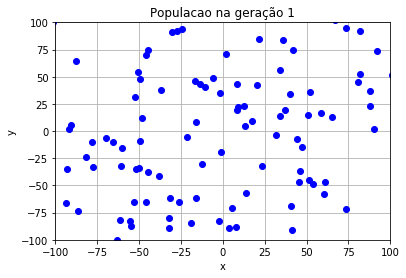

In [11]:
#Teste

print('============================')
vParticles = runEpoch(vParticles)
plot_population(vParticles, 1)
gBest = calcGBest(vParticles)

## Validação

    print('============================')
    vParticles = runEpoch(vParticles)
    plot_population(vParticles, 1)
    gBest = calcGBest(vParticles)


### Observe se ocorre convergência